# 01 Rules: a rule written for a different body

*Teaching material. Not for clinical use.*

A casualty has air trapped under pressure in the chest, and it has to be let out. The guidance recommended doing it with a needle of about 5 cm pushed through the chest wall. In 100 male military casualties imaged by CT, the chest wall was 5.36 cm thick on average (E-104).

**Before reading on, guess.** When the standard needle was used in the field, what happened?

- Almost every decompression worked: a few millimetres either way do not matter
- A few failed
- A large share needed something more
- Nothing can be said without a trial

Write the guess down. It is not marked, and the answer comes in the failure section below.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline
from inference_labs.lenses import bayesian as bayes
from inference_labs.lenses import rules

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID = "#7f2704", "#d9d9d9", "#08306b"   # needs intervention, does not, published figure
PALE = "#6baed6"                                      # a second series: lighter, and drawn hollow or hatched
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)

# 100,000 synthetic casualties, seed 42, military cohort, every stream. Every result on them is a mechanism.
observed, truth = baseline.generator_sample()

## The idea, before any medicine

A recipe says: bake for 25 minutes at 180 degrees. Someone worked that out once, in their own oven, so that nobody would have to think about it with guests at the door. It is quick, it gives the same answer every time, and it is usually right.

It is also blind. It does not know that this oven runs hot, or that this tin is twice the size. The recipe carries the kitchen it was written in, and nothing on the page says so.

**Plain.** A rule is a decision someone made in advance so that nobody has to think under pressure. It is fast, the same every time, and blind to anything it was not written for. Three questions tell you most of what you need to know about one: where did it come from, who was it written for, and what does it throw away?

**Developer.** A rule is a function with no learned state: a fixed sequence of yes-or-no tests, each of which either returns an answer or passes the case on. The MPTT-24, a military triage rule, is six such tests. It costs six comparisons a casualty and needs no data at the point of use.

```python
def mptt24(c, reading="figure"):
    if c.catastrophic_haemorrhage:          return "Priority 1"   # tourniquet or haemostatic dressing
    if c.walking:                           return "Priority 3"
    if not c.breathing:                     return "Dead"
    if c.avpu in ("P", "U") or (reading == "text" and c.avpu == "V"):
                                            return "Priority 1"   # recovery position
    if not 12 <= c.respiratory_rate <= 23:  return "Priority 1"
    return "Priority 2" if c.heart_rate < 100 else "Priority 1"
```

**Technical.** A rule $f$ maps observations $x$ to a decision. Read as a fast-and-frugal tree, the choice of exits sets where the decision criterion lies (E-59). Of the MPTT-24's five steps before the last, three send a casualty straight to Priority 1, one to Dead and one, walking, to Priority 3, and the last splits Priority 1 from Priority 2. Five of its seven ways out lead to Priority 1 or Dead: a liberal criterion written as a flowchart. Its accuracy is not a property of $f$ alone. For a population in which the observations given the condition $D$ follow $p(x \mid D)$, and a share $\pi$ has the condition,

$$\mathrm{sens} = P\big(f(X) = 1 \mid D = 1\big) = \sum_x \mathbf{1}[f(x) = 1]\; p(x \mid D = 1), \qquad \mathrm{PPV} = \frac{\mathrm{sens}\;\pi}{\mathrm{sens}\;\pi + (1 - \mathrm{spec})(1 - \pi)}.$$

The same $f$ therefore has a different sensitivity wherever $p(x \mid D)$ differs, and a different positive predictive value wherever $\pi$ differs, even when its sensitivity and specificity do not.

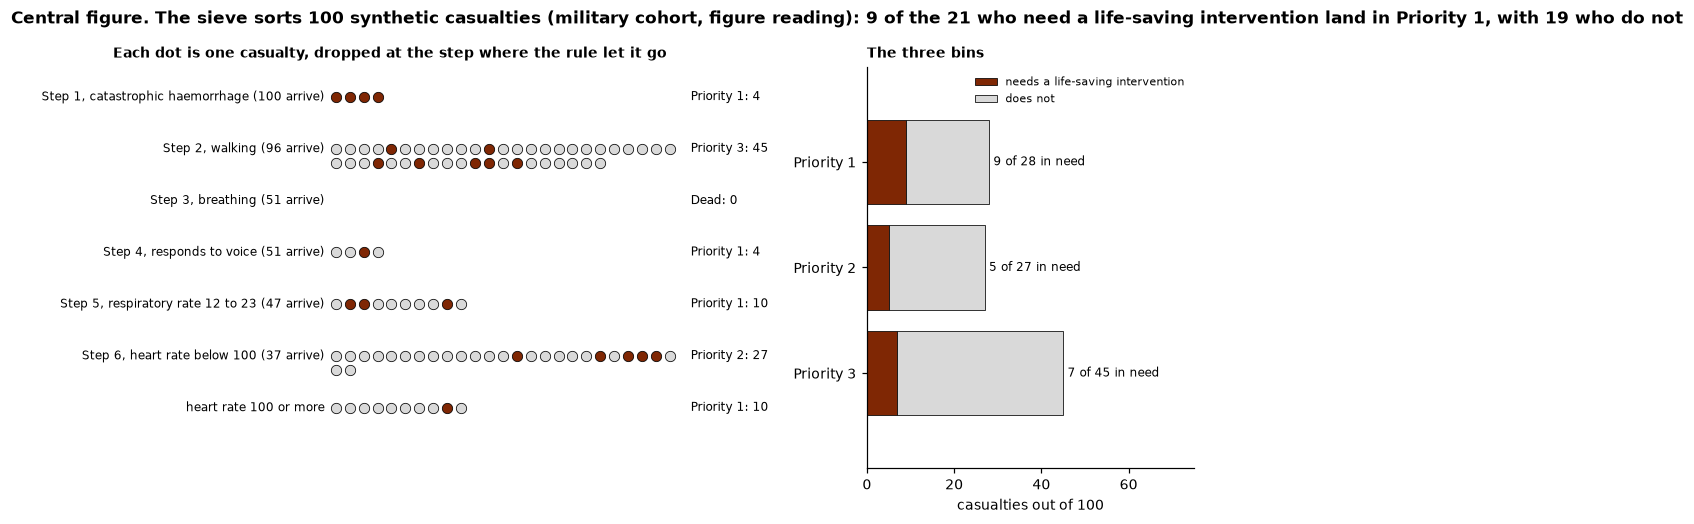

In [2]:
# Central figure: the sieve. The controls: change them and run the cell again.
READING = "figure"     # "figure" (as published, the default) or "text"
COHORT = "military"    # "military" or "civilian": whose accuracy the generator's physiology reproduces

obs_c, tru_c = baseline.generator_sample("pre_hospital", COHORT)
hundred, need = obs_c.head(100), tru_c["needs_lsi"].head(100).to_numpy()
sieve = baseline.triage_table(hundred, READING)
exits = [(1, baseline.P1), (2, baseline.P3), (3, baseline.DEAD), (4, baseline.P1), (5, baseline.P1),
         (6, baseline.P2), (6, baseline.P1)]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [3.2, 1.6]})
for k, (step, priority) in enumerate(exits):
    members = np.flatnonzero(((sieve["step"] == step) & (sieve["priority"] == priority)).to_numpy())
    arriving = int((sieve["step"] >= step).sum())
    y = -1.2 * k
    gate = f"Step {step}, {baseline.STEPS[step - 1]} ({arriving} arrive)" if k < 6 else f"heart rate {baseline.HR_BELOW} or more"
    ax.text(-0.8, y, gate, ha="right", va="center", fontsize=8)
    for i, m in enumerate(members):
        ax.scatter(i % 25, y - 0.32 * (i // 25), s=46, color=DARK if need[m] else LIGHT, edgecolor="black",
                   linewidth=0.5, zorder=3)
    ax.text(25.5, y, f"{priority}: {len(members)}", va="center", fontsize=8)
ax.set_xlim(-16, 31)
ax.set_ylim(-1.2 * len(exits) - 0.2, 0.7)
ax.axis("off")
ax.set_title("Each dot is one casualty, dropped at the step where the rule let it go", loc="left", fontsize=9)

bins = [baseline.P1, baseline.P2, baseline.P3]
in_need = [int(((sieve["priority"] == p).to_numpy() & need).sum()) for p in bins]
not_in_need = [int(((sieve["priority"] == p).to_numpy() & ~need).sum()) for p in bins]
bx.barh(bins, in_need, color=DARK, edgecolor="black", linewidth=0.5, label="needs a life-saving intervention")
bx.barh(bins, not_in_need, left=in_need, color=LIGHT, edgecolor="black", linewidth=0.5, label="does not")
for i, (a, b) in enumerate(zip(in_need, not_in_need)):
    bx.text(a + b + 1, i, f"{a} of {a + b} in need", va="center", fontsize=8)
bx.set_xlim(0, 75)
bx.set_xlabel("casualties out of 100")
bx.legend(fontsize=7, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.0))
bx.set_ylim(2.9, -0.9)
bx.set_title("The three bins", loc="left", fontsize=9)
hit, total = in_need[0], int(need.sum())
fig.suptitle(f"Central figure. The sieve sorts 100 synthetic casualties ({COHORT} cohort, {READING} reading): "
             f"{hit} of the {total} who need a life-saving intervention land in Priority 1, with {not_in_need[0]} who do not",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

The figure counts people, not probabilities. Each dot is one synthetic casualty from the generator, and the dark ones need a life-saving intervention. These are **mechanism** results: the generator drew its physiology so that the rule, read the way its published accuracy was measured, reproduces that accuracy. The sieve can show only what the rule does to casualties built that way.

Change `READING` or `COHORT` at the top of the cell and run it again: the same hundred re-sort.

## By hand: ten casualties through six steps

Ten synthetic casualties from the generator, chosen from its first fifty so that every exit it can produce appears at least once. They are chosen, not drawn at random, so how often each exit appears here says nothing about how common it is. The generator records no breathing check, and every casualty it draws is taken as breathing, an assumption; so nobody here leaves at step 3.

Take each row in turn and ask the six questions in order. Stop at the first that gives an answer.

In [3]:
TEN = [1, 2, 3, 4, 10, 13, 14, 20, 30, 50]
columns = ["catastrophic_haemorrhage", "walking", "avpu", "respiratory_rate", "heart_rate"]
ten = observed.loc[observed["id"].isin(TEN), ["id"] + columns].set_index("id")
ten

,catastrophic_haemorrhage,walking,avpu,respiratory_rate,heart_rate
id,,,,,
1,False,False,A,20,63
2,False,True,A,12,79
3,False,False,A,12,104
4,False,False,A,18,95
10,False,False,A,13,136
13,False,True,A,14,96
14,False,False,U,20,75
20,False,False,A,38,81
30,True,False,A,12,117


Four of them on paper:

- **Casualty 1** is not bleeding catastrophically, is not walking, is breathing and alert. A respiratory rate of 20 is inside 12 to 23, and a heart rate of 63 is below 100. Priority 2, at the last step.
- **Casualty 2** is walking, so leaves at step 2 for Priority 3 before anyone counts a breath.
- **Casualty 30** is bleeding catastrophically and leaves at step 1 for Priority 1, whatever else is true. The flowchart's instruction there is a tourniquet or haemostatic dressing.
- **Casualty 50** responds to voice but is not alert. The published figure lets that casualty go on: a respiratory rate of 12 and a heart rate of 90 then give Priority 2. The paper's text would have stopped at step 4 with Priority 1.

Work the other six by hand before running the next cell. Then the same six questions in plain Python, checked against the library.

In [4]:
def by_hand(c, reading="figure"):
    if c["catastrophic_haemorrhage"]:
        return "Priority 1", 1
    if c["walking"]:
        return "Priority 3", 2
    # step 3, breathing: the generator records no breathing check, so every casualty is taken as breathing
    leaves_at_voice = ("P", "U") if reading == "figure" else ("V", "P", "U")
    if c["avpu"] in leaves_at_voice:
        return "Priority 1", 4
    if not 12 <= c["respiratory_rate"] <= 23:
        return "Priority 1", 5
    return ("Priority 2" if c["heart_rate"] < 100 else "Priority 1"), 6


rows = []
for cid, c in ten.iterrows():
    figure_priority, figure_step = by_hand(c, "figure")
    text_priority, _ = by_hand(c, "text")
    library = baseline.triage(c.to_dict())
    assert (library.priority, library.step) == (figure_priority, figure_step)   # the library agrees with the hand count
    rows.append({"casualty": cid, "left at step": figure_step, "priority, figure": figure_priority,
                 "priority, text": text_priority,
                 "needs a life-saving intervention": bool(truth.loc[observed["id"] == cid, "needs_lsi"].iloc[0])})
by_hand_table = pd.DataFrame(rows).set_index("casualty")
by_hand_table

,left at step,"priority, figure","priority, text",needs a life-saving intervention
casualty,,,,
1,6,Priority 2,Priority 2,False
2,2,Priority 3,Priority 3,False
3,6,Priority 1,Priority 1,False
4,6,Priority 2,Priority 2,False
10,6,Priority 1,Priority 1,False
13,2,Priority 3,Priority 3,True
14,4,Priority 1,Priority 1,False
20,5,Priority 1,Priority 1,False
30,1,Priority 1,Priority 1,True


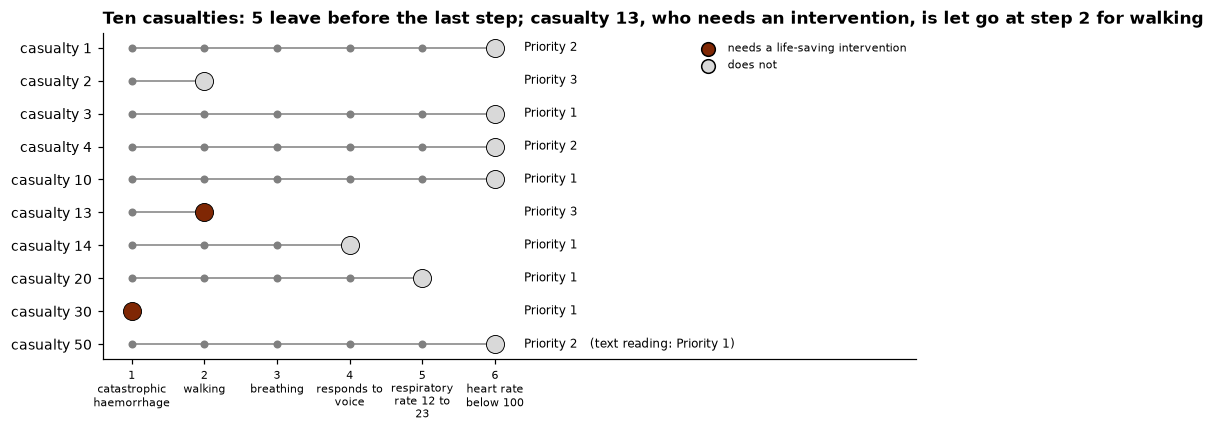

In [5]:
import textwrap

fig, ax = plt.subplots(figsize=(8.5, 4.0))
for row, (cid, r) in enumerate(by_hand_table.iterrows()):
    y, step = -row, int(r["left at step"])
    ax.plot([1, step], [y, y], color="grey", linewidth=1, zorder=1)
    ax.scatter(range(1, step), [y] * (step - 1), s=18, color="grey", zorder=2)
    ax.scatter([step], [y], s=140, color=DARK if r["needs a life-saving intervention"] else LIGHT,
               edgecolor="black", linewidth=0.6, zorder=3)
    note = r["priority, figure"]
    if r["priority, figure"] != r["priority, text"]:
        note += f"   (text reading: {r['priority, text']})"
    ax.text(6.4, y, note, va="center", fontsize=8)
ax.set_yticks([-i for i in range(len(by_hand_table))], [f"casualty {c}" for c in by_hand_table.index])
ax.set_xticks(range(1, 7), [f"{k}\n" + "\n".join(textwrap.wrap(name, 12, break_long_words=False)) for k, name in enumerate(baseline.STEPS, start=1)],
              fontsize=7)
ax.set_xlim(0.6, 11.8)
ax.scatter([], [], s=80, color=DARK, edgecolor="black", label="needs a life-saving intervention")
ax.scatter([], [], s=80, color=LIGHT, edgecolor="black", label="does not")
ax.legend(fontsize=7, frameon=False, loc="upper right")
early = int((by_hand_table["left at step"] < 6).sum())
missed = by_hand_table[(by_hand_table["priority, figure"] != "Priority 1") & by_hand_table["needs a life-saving intervention"]]
ax.set_title(f"Ten casualties: {early} leave before the last step; casualty {missed.index[0]}, who needs an "
             "intervention, is let go at step 2 for walking", loc="left")
plt.tight_layout()
plt.show()

That table is the rule. The library runs the same six steps on all 100,000 synthetic casualties at once. Written as notation, the rule is a decision list:

$$f(x) = \begin{cases} \text{Priority 1} & \text{if catastrophic haemorrhage} \\ \text{Priority 3} & \text{else if walking} \\ \text{Dead} & \text{else if not breathing} \\ \text{Priority 1} & \text{else if } \mathrm{AVPU} \in V_r \\ \text{Priority 1} & \text{else if } \mathrm{RR} \notin [12, 23] \\ \text{Priority 2} & \text{else if } \mathrm{HR} < 100 \\ \text{Priority 1} & \text{otherwise,} \end{cases} \qquad V_{\text{figure}} = \{P, U\}, \quad V_{\text{text}} = \{V, P, U\}.$$

In [6]:
sorted_all = baseline.triage_table(observed)
exits_all = sorted_all.groupby(["step", "priority"]).size().rename("synthetic casualties").reset_index()
exits_all.insert(1, "step name", exits_all["step"].map(lambda s: baseline.STEPS[s - 1]))
exits_all.set_index(["step", "step name", "priority"])

synthetic casualties
step step name                 priority                        
1    catastrophic haemorrhage  Priority 1                  2290
2    walking                   Priority 3                 37979
4    responds to voice         Priority 1                  3358
5    respiratory rate 12 to 23 Priority 1                 10357
6    heart rate below 100      Priority 1                 16890
                               Priority 2                 29126

## Diagnosis: which priority, and how often is it right?

### First, a check on the generator

The MPTT-24 was tested in the UK military registry, 3,654 adults, on a cohort in which 47.6% were Priority 1: sensitivity 66.7% and specificity 69.9% for finding them (E-09). That test used the first recorded hospital respiratory rate and registry GCS, not observations at the point of injury (E-09, E-11). Where the rule has its voice step, the test had GCS, and the paper's text says 'responds to voice' replaces 'GCS below 14' (E-08). The reading that matches what was tested is therefore the text reading, and the check below uses it.

The generator drew its physiology so that the rule would reproduce that accuracy. The check therefore tests the generator, not the rule: agreement means only that the synthetic casualties are built consistently with E-09. The figure reading is shown beside it and is not held to E-09.

In [7]:
baseline.calibration_check("military")

,reading,measure,E-09,achieved,tolerance,held to E-09,within tolerance
0,figure,sensitivity,0.667,0.611,0.015,False,False
1,figure,specificity,0.699,0.728,0.010,False,False
2,text,sensitivity,0.667,0.665,0.015,True,True
3,text,specificity,0.699,0.697,0.010,True,True


### A one-word ambiguity

The paper's text and its figure disagree for one group: casualties who respond to voice but are not alert (E-08). Read literally, the figure lets them through to the respiratory rate and heart rate; the text makes them Priority 1. The default here is the figure, as published. Count what the difference does.

In [8]:
changes = baseline.reading_changes(observed)
moved_need = truth.loc[changes.index, "needs_lsi"].to_numpy(bool)
down = int(((changes["text"] == baseline.P1) & (changes["figure"] == baseline.P2)).sum())
print(f"synthetic casualties, military cohort, seed 42           {len(observed):,}")
print(f"priority differs between the two readings              {len(changes):,}")
print(f"  Priority 1 under the text, Priority 2 under the figure {down:,}")
print(f"  of those, needing a life-saving intervention          {int(moved_need.sum()):,}")
print(f"  of those, not needing one                             {int((~moved_need).sum()):,}")

synthetic casualties, military cohort, seed 42           100,000
priority differs between the two readings              3,446
  Priority 1 under the text, Priority 2 under the figure 3,446
  of those, needing a life-saving intervention          917
  of those, not needing one                             2,529


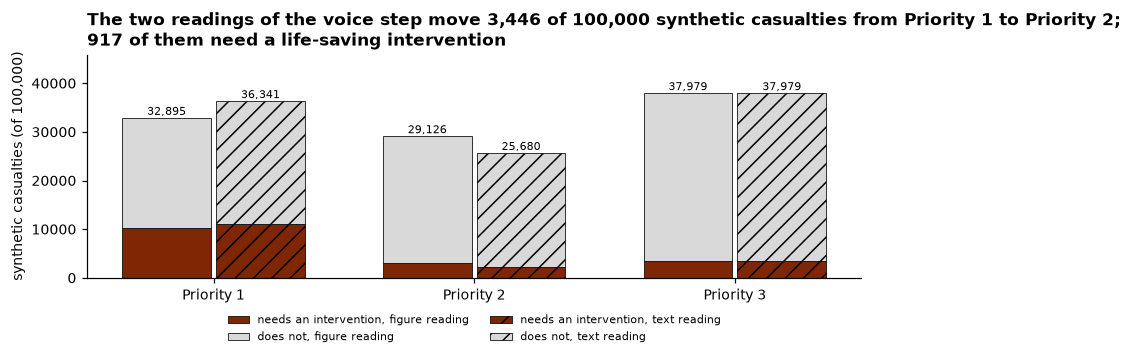

In [9]:
need_all = truth["needs_lsi"].to_numpy(bool)
bins = [baseline.P1, baseline.P2, baseline.P3]
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, (reading, hatch) in enumerate((("figure", ""), ("text", "//"))):
    pr = baseline.triage_table(observed, reading)["priority"].to_numpy()
    x = np.arange(len(bins)) + (j - 0.5) * 0.36
    a = [int(((pr == p) & need_all).sum()) for p in bins]
    b = [int(((pr == p) & ~need_all).sum()) for p in bins]
    ax.bar(x, a, 0.34, color=DARK, hatch=hatch, edgecolor="black", linewidth=0.5,
           label=f"needs an intervention, {reading} reading")
    ax.bar(x, b, 0.34, bottom=a, color=LIGHT, hatch=hatch, edgecolor="black", linewidth=0.5,
           label=f"does not, {reading} reading")
    for xi, ai, bi in zip(x, a, b):
        ax.text(xi, ai + bi + 600, f"{ai + bi:,}", ha="center", fontsize=7)
ax.set_xticks(range(len(bins)), bins)
ax.set_ylabel("synthetic casualties (of 100,000)")
ax.legend(fontsize=7, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.set_title(f"The two readings of the voice step move {len(changes):,} of 100,000 synthetic casualties from "
             f"Priority 1 to Priority 2;\n{int(moved_need.sum()):,} of them need a life-saving intervention", loc="left")
plt.tight_layout()
plt.show()

The size of that number is set by the generator, not by the rule. The generator assumes that half of the casualties who are not alert respond to voice, and that each Priority 1 casualty has exactly one abnormal sign, so a casualty who responds only to voice, unless bleeding catastrophically, has a normal respiratory rate and heart rate and ends in Priority 2 under the figure. What the rule itself fixes is the direction: the figure reading can only move a casualty down from Priority 1, never up. In the check above, that is why the figure reading's sensitivity is lower and its specificity higher than E-09's.

### Beside the rule it replaced

The Military Sieve is not coded here. The register holds its performance, not its algorithm (E-10), so it appears only as published figures from the same paper, in the same military registry, again on first hospital observations (E-11). There the MPTT-24 had sensitivity 66.7% and specificity 69.9%; the Military Sieve had 43.2% and 93.7% (E-09, E-10). The newer rule finds more of those who need intervention and wrongly flags more of those who do not.

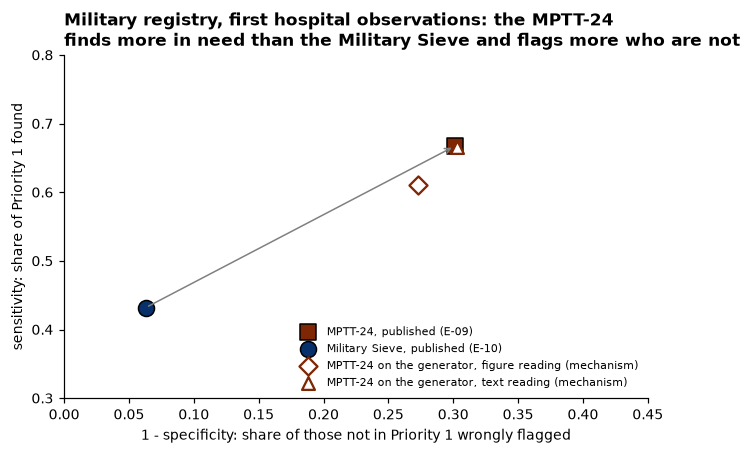

In [10]:
mil, sieve = rules.PUBLISHED["MPTT-24, military"], rules.PUBLISHED["Military Sieve, military"]
generated = {reading: baseline.diagnosis_results("pre_hospital", reading) for reading in baseline.READINGS}

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(1 - mil.specificity, mil.sensitivity, s=110, marker="s", color=DARK, edgecolor="black", zorder=3,
           label="MPTT-24, published (E-09)")
ax.scatter(1 - sieve.specificity, sieve.sensitivity, s=110, marker="o", color=MID, edgecolor="black", zorder=3,
           label="Military Sieve, published (E-10)")
for reading, marker in (("figure", "D"), ("text", "^")):
    r = generated[reading]
    ax.scatter(1 - r["specificity"], r["sensitivity"], s=70, marker=marker, facecolor="white", edgecolor=DARK,
               linewidth=1.5, zorder=4, label=f"MPTT-24 on the generator, {reading} reading (mechanism)")
ax.annotate("", xy=(1 - mil.specificity, mil.sensitivity), xytext=(1 - sieve.specificity, sieve.sensitivity),
            arrowprops={"arrowstyle": "->", "color": "grey"})
ax.set_xlim(0, 0.45)
ax.set_ylim(0.3, 0.8)
ax.set_xlabel("1 - specificity: share of those not in Priority 1 wrongly flagged")
ax.set_ylabel("sensitivity: share of Priority 1 found")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("Military registry, first hospital observations: the MPTT-24\nfinds more in need than the Military Sieve "
             "and flags more who are not", loc="left")
plt.tight_layout()
plt.show()

None of these figures is performance at the point of injury. The MPTT-24 has not been validated on pre-hospital observations: complete pre-hospital data existed for only 16.7% of the military cases and 37.2% of the civilian ones (E-11). On the generator the physiology is the same whichever setting is chosen, so it cannot show what moving from hospital observations to the point of injury would do either.

## Treatment: when do the rules say transfuse, and when tranexamic acid?

This section is about treatment decisions, and its results are kept apart from the diagnosis results above.

### The ABC score

The ABC score counts four yes-or-no items: a penetrating mechanism, a positive scan, a systolic pressure of 90 mm Hg or less, and a heart rate of 120 or more. A score of 2 or more activates massive transfusion. In the paper that introduced it, among 596 patients of whom 12.4% were massively transfused, a score of 2 or more was 75% sensitive and 86% specific (E-31). The register does not describe those patients as military, so applying the score to a military casualty is an assumption.

The generator records neither penetration nor massive transfusion, so three more assumptions are needed:

- small arms injuries count as penetrating; explosion and other mechanisms do not;
- significant bleeding stands in for the need for transfusion;
- the scan item is the generator's scan for free fluid, before hospital or in hospital.

The generator's pressure and pulse were drawn to make the MPTT-24, not the ABC score, reproduce published figures. What follows shows how the score behaves on casualties built that way. It is driven mainly by those assumptions and is not a measure of the score in military casualties.

In [11]:
rows = []
for setting in baseline.SETTINGS:
    result = rules.treatment_results(setting)
    for flag, key in (("ABC score 2 or more", "abc"), ("MPTT-24 Priority 1, the baseline", "mptt24")):
        r = result[key]
        rows.append({"scan": baseline.SETTING_NAMES[setting], "flag": flag, "battle casualties": r["casualties"],
                     "sensitivity for significant bleeding": r["sensitivity"], "specificity": r["specificity"]})
pd.DataFrame(rows).set_index(["scan", "flag"]).round(3)

battle casualties  \
scan                 flag                                                  
scan before hospital ABC score 2 or more                           29925   
                     MPTT-24 Priority 1, the baseline              29925   
scan in hospital     ABC score 2 or more                           29925   
                     MPTT-24 Priority 1, the baseline              29925   

                                                       sensitivity for significant bleeding  \
scan                 flag                                                                     
scan before hospital ABC score 2 or more                                              0.233   
                     MPTT-24 Priority 1, the baseline                                 0.620   
scan in hospital     ABC score 2 or more                                              0.311   
                     MPTT-24 Priority 1, the baseline                                 0.620   

                                                       specificity  
scan                 flag                                           
scan before hospital ABC score 2 or more                     0.932  
                     MPTT-24 Priority 1, the baseline        0.659  
scan in hospital     ABC score 2 or more                     0.941  
                     MPTT-24 Priority 1, the baseline        0.659

In [12]:
battle_obs, battle_truth = rules.battle_sample("pre_hospital")
items = rules.abc_table(battle_obs)
with_explosions = items["score"] + battle_obs["mechanism"].eq("explosion").to_numpy()
print(f"battle casualties activated, small arms counted as penetrating   {(items['score'] >= 2).mean():.1%}")
print(f"battle casualties activated, explosions counted as well          {(with_explosions >= 2).mean():.1%}")

battle casualties activated, small arms counted as penetrating   12.8%
battle casualties activated, explosions counted as well          24.3%


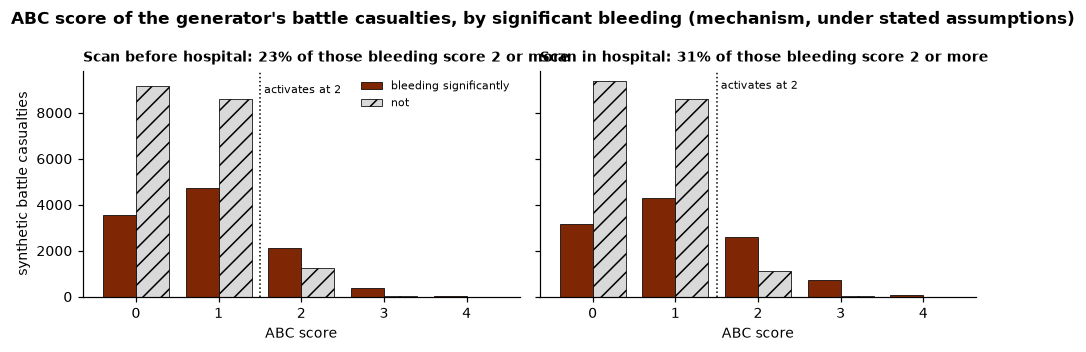

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
scores = np.arange(5)
for ax, setting in zip(axes, baseline.SETTINGS):
    obs_s, tru_s = rules.battle_sample(setting)
    score = rules.abc_table(obs_s)["score"].to_numpy()
    bleed = tru_s["bleeding"].to_numpy(bool)
    a = [int(((score == s) & bleed).sum()) for s in scores]
    b = [int(((score == s) & ~bleed).sum()) for s in scores]
    ax.bar(scores - 0.2, a, 0.4, color=DARK, edgecolor="black", linewidth=0.5, label="bleeding significantly")
    ax.bar(scores + 0.2, b, 0.4, color=LIGHT, edgecolor="black", linewidth=0.5, hatch="//", label="not")
    ax.axvline(1.5, color="black", linestyle=":", linewidth=1)
    ax.text(1.55, ax.get_ylim()[1] * 0.92, "activates at 2", fontsize=7)
    sens = rules.treatment_results(setting)["abc"]["sensitivity"]
    ax.set_title(f"Scan {baseline.SETTING_NAMES[setting][5:]}: {sens:.0%} of those bleeding score 2 or more",
                 loc="left", fontsize=9)
    ax.set_xlabel("ABC score")
axes[0].set_ylabel("synthetic battle casualties")
axes[0].legend(fontsize=7, frameon=False)
fig.suptitle("ABC score of the generator's battle casualties, by significant bleeding (mechanism, under stated assumptions)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### What the score throws away

The score counts a positive scan as one point, wherever the scan was done. In the Bayesian lens, starting from one casualty in five (the assumption used there), a positive scan moves the belief to about 65% before hospital and about 90% in hospital. Those beliefs rest on scan accuracy from civilian studies (E-16 before hospital; E-14 in hospital, where the shape of the uncertainty is itself an assumption), so carrying them to a military casualty is an assumption too. The score gives both one point. That loss is the price of a rule that can be counted on the fingers, and it is the comparison the Bayesian lens exists to make.

In [14]:
for setting in bayes.SETTINGS:
    belief = bayes.belief_after_scan(0.20, setting)
    lo, hi = belief.interval()
    print(f"positive scan {bayes.SETTING_NAMES[setting]:16s} belief {belief.mean():.0%} ({lo:.0%} to {hi:.0%})"
          f"   points it adds to the ABC score: 1")

positive scan before hospital  belief 65% (48% to 82%)   points it adds to the ABC score: 1
positive scan in hospital      belief 90% (82% to 96%)   points it adds to the ABC score: 1


### The doctrine's four items

US military resuscitation doctrine names four predictors of massive transfusion: systolic pressure under 100, heart rate over 100, haematocrit under 32% and pH under 7.25. Three of the four predict about a 70% risk, and all four about 85% (E-86). Two of the four need a laboratory. At the point of injury only pressure and pulse can be read, so a casualty can show at most two, and the rule cannot be met there.

In [15]:
bedside = rules.doctrine_bedside_table(battle_obs)
print(f"synthetic battle casualties                              {len(battle_obs):,}")
for k in (0, 1, 2):
    print(f"  showing {k} of the two bedside items                     {int((bedside == k).sum()):,}")
print(f"  reaching three of four without a laboratory            {int((bedside >= rules.DOCTRINE_NEEDS).sum()):,}")

synthetic battle casualties                              29,925
  showing 0 of the two bedside items                     19,773
  showing 1 of the two bedside items                     8,750
  showing 2 of the two bedside items                     1,402
  reaching three of four without a laboratory            0


### Tranexamic acid within three hours

The same doctrine gives tranexamic acid only if it can be started within 3 hours of injury (E-86). That limit is not an opinion: it is the time-to-treatment result of a trial, written as an instruction. In CRASH-2, among those treated within an hour of injury, 5.3% died from bleeding with tranexamic acid against 7.7% with placebo, a relative risk of 0.68 (0.57 to 0.82). Between one and three hours it was 4.8% against 6.1%, a relative risk of 0.79 (0.64 to 0.97). After three hours it was 4.4% against 3.1%, a relative risk of 1.44 (1.12 to 1.84): **more** of those treated late died from bleeding with tranexamic acid than with placebo (E-22). The analysis by time was exploratory, not a prespecified primary result (E-23), and the rule does not say so. CRASH-2 is civilian, so applying its figures to a military casualty is an assumption.

On the generator, the time from injury to pre-hospital care is an assumption, chosen so that the generator reproduces those bands.

In [16]:
minutes = battle_obs["t_phec_min"]
inside = minutes.map(rules.txa_inside)
print(f"synthetic battle casualties reaching pre-hospital care within 3 hours of injury: "
      f"{inside.mean():.1%} ({int(inside.sum()):,} of {len(inside):,})")

synthetic battle casualties reaching pre-hospital care within 3 hours of injury: 99.0% (29,613 of 29,925)


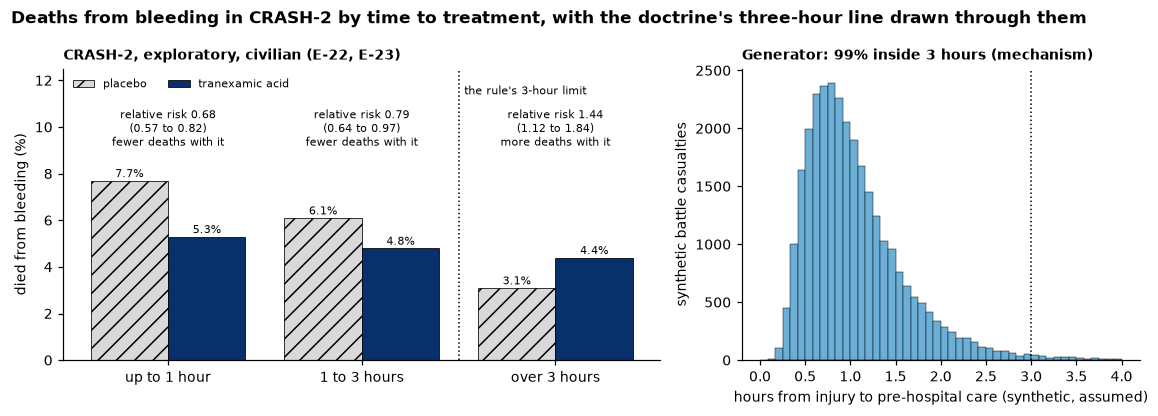

In [17]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(len(rules.E22_BANDS))
treated = [b["tranexamic acid"] for b in rules.E22_BANDS]
placebo = [b["placebo"] for b in rules.E22_BANDS]
ax.bar(x - 0.2, placebo, 0.4, color=LIGHT, edgecolor="black", linewidth=0.5, hatch="//", label="placebo")
ax.bar(x + 0.2, treated, 0.4, color=MID, edgecolor="black", linewidth=0.5, label="tranexamic acid")
for xi, band in zip(x, rules.E22_BANDS):
    rr, lo, hi = band["rr"]
    ax.text(xi - 0.2, band["placebo"] + 0.15, f"{band['placebo']}%", ha="center", fontsize=7)
    ax.text(xi + 0.2, band["tranexamic acid"] + 0.15, f"{band['tranexamic acid']}%", ha="center", fontsize=7)
    words = "fewer deaths with it" if hi < 1 else "more deaths with it"
    ax.text(xi, 9.2, f"relative risk {rr}\n({lo} to {hi})\n{words}", ha="center", fontsize=7)
ax.axvline(1.5, color="black", linestyle=":", linewidth=1)
ax.text(1.53, 11.4, "the rule's 3-hour limit", fontsize=7)
ax.set_xticks(x, [b["band"] for b in rules.E22_BANDS])
ax.set_ylim(0, 12.5)
ax.set_ylabel("died from bleeding (%)")
ax.legend(fontsize=7, frameon=False, loc="upper left", ncol=2)
ax.set_title("CRASH-2, exploratory, civilian (E-22, E-23)", loc="left", fontsize=9)

bx.hist(minutes / 60, bins=np.linspace(0, 4, 49), color=PALE, edgecolor="black", linewidth=0.3)
bx.axvline(3, color="black", linestyle=":", linewidth=1)
bx.set_xlabel("hours from injury to pre-hospital care (synthetic, assumed)")
bx.set_ylabel("synthetic battle casualties")
bx.set_title(f"Generator: {inside.mean():.0%} inside 3 hours (mechanism)", loc="left", fontsize=9)
fig.suptitle("Deaths from bleeding in CRASH-2 by time to treatment, with the doctrine's three-hour line drawn through them",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## The failure: a rule meeting a body it was not written for

Back to the hook. A needle of about 5 cm was recommended. In 100 male military casualties imaged by CT, the chest wall was 5.36 cm thick on average, with a standard deviation of 1.19 cm, and an 8 cm catheter would have reached in 99% (E-104). The rule was written for a different body.

How many of those chests would the 5 cm needle cross? The summary gives a mean and a spread, not the hundred measurements, so assume the thicknesses follow a normal curve with that mean and spread. The shape is an assumption. It can be checked against the one other figure given, the 99% for an 8 cm catheter. A needle is taken to reach when it is longer than the chest wall is thick, which ignores the angle of insertion and the hub. The population is male only.

In [18]:
reach_needle = rules.needle_reaches(rules.NEEDLE_CM)
reach_catheter = rules.needle_reaches(rules.CATHETER_CM)
print(f"5 cm needle crosses the chest wall     {reach_needle:.1%}   (assumed normal shape)")
print(f"8 cm catheter crosses the chest wall   {reach_catheter:.1%}   (assumed shape; E-104 reports 99%)")

5 cm needle crosses the chest wall     38.1%   (assumed normal shape)
8 cm catheter crosses the chest wall   98.7%   (assumed shape; E-104 reports 99%)


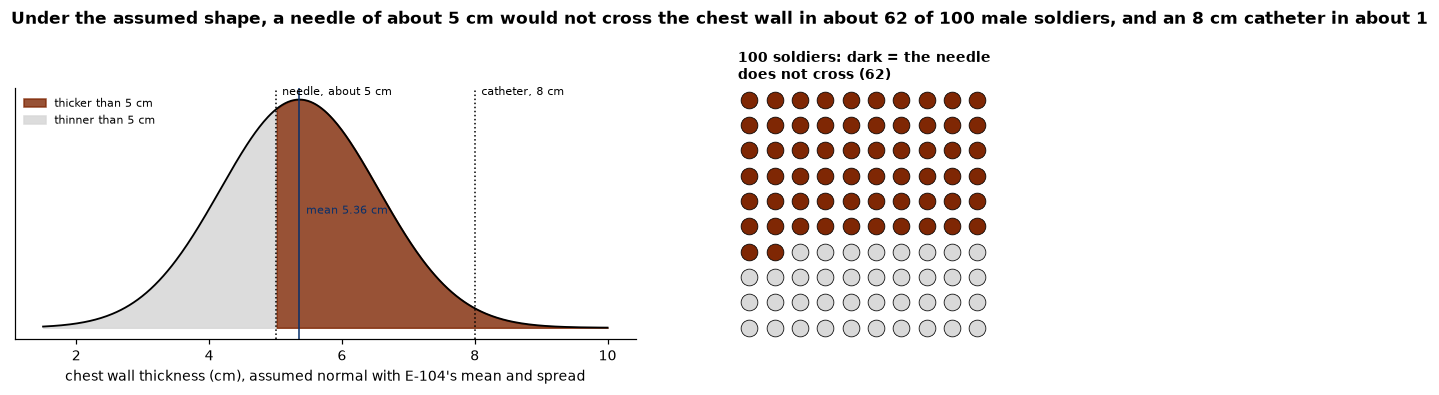

In [19]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
cm = np.linspace(1.5, 10, 400)
density = np.exp(-0.5 * ((cm - rules.CHEST_WALL_MEAN_CM) / rules.CHEST_WALL_SD_CM) ** 2)
ax.plot(cm, density, color="black", linewidth=1.2)
ax.fill_between(cm, density, where=cm > rules.NEEDLE_CM, color=DARK, alpha=0.8, label="thicker than 5 cm")
ax.fill_between(cm, density, where=cm <= rules.NEEDLE_CM, color=LIGHT, alpha=0.9, label="thinner than 5 cm")
for length, words in ((rules.NEEDLE_CM, "needle, about 5 cm"), (rules.CATHETER_CM, "catheter, 8 cm")):
    ax.axvline(length, color="black", linestyle=":", linewidth=1)
    ax.text(length + 0.1, 1.02, words, fontsize=7)
ax.axvline(rules.CHEST_WALL_MEAN_CM, color=MID, linewidth=1)
ax.text(rules.CHEST_WALL_MEAN_CM + 0.1, 0.5, "mean 5.36 cm", fontsize=7, color=MID)
ax.set_yticks([])
ax.set_xlabel("chest wall thickness (cm), assumed normal with E-104's mean and spread")
ax.legend(fontsize=7, frameon=False, loc="upper left")

fail = round(100 * (1 - reach_needle))
for k in range(100):
    bx.scatter(k % 10, -(k // 10), s=120, color=DARK if k < fail else LIGHT, edgecolor="black", linewidth=0.5)
bx.set_aspect("equal")
bx.axis("off")
bx.set_title(f"100 soldiers: dark = the needle\ndoes not cross ({fail})", loc="left", fontsize=9)
fig.suptitle(f"Under the assumed shape, a needle of about 5 cm would not cross the chest wall in about {fail} of 100 "
             f"male soldiers, and an 8 cm catheter in about {round(100 * (1 - reach_catheter))}",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**The answer to the hook.** In the field record, 111 casualties had a needle decompression between 1997 and 2012, 79% of them at the point of injury, and 32% then had a chest tube placed in the field. The authors conclude that the standard needle has a high failure rate on the battlefield (E-106). The record has no comparison group, so it does not show how often the needle failed, only that about a third of those decompressed went on to have a chest tube. It points the same way as the measurements; it is not a test of them.

### The same failure, twice more

The needle rule failed by meeting a body thicker than it was written for. The MPTT-24 meets the same failure when it leaves the military registry. In the civilian registry, TARN, 127,233 patients of whom 19.5% were Priority 1, its sensitivity was 53.5% and its specificity 74.8%, against 66.7% and 69.9% in the military registry, where 47.6% were Priority 1 (E-09). Nothing in the rule changed. Both are on first hospital observations (E-11).

The share of Priority 1 moves the predictive value further. Of those the rule called Priority 1, 67.0% were Priority 1 in the military registry and 34.0% in the civilian one (E-09). Both follow, to within rounding, from the accuracy and the share, by Bayes' rule.

In [20]:
for key in ("MPTT-24, military", "MPTT-24, civilian"):
    p = rules.PUBLISHED[key]
    print(f"{p.population:52s} Priority 1 {p.prevalence:.1%}  sensitivity {p.sensitivity:.1%}  "
          f"specificity {p.specificity:.1%}  -> predictive value {rules.ppv(p.sensitivity, p.specificity, p.prevalence):.1%}"
          f"  (published {p.ppv:.1%}, {p.source})")

UK military registry (JTTR), 3,654 adults, 2006 to 2013 Priority 1 47.6%  sensitivity 66.7%  specificity 69.9%  -> predictive value 66.8%  (published 67.0%, E-09)
civilian registry (TARN), 127,233 patients           Priority 1 19.5%  sensitivity 53.5%  specificity 74.8%  -> predictive value 34.0%  (published 34.0%, E-09)


The generator's civilian cohort is built to reproduce the civilian figures, so on it the coded rule meets them by construction. That is a check on the generator, not a second finding:

In [21]:
baseline.calibration_check("civilian")

,reading,measure,E-09,achieved,tolerance,held to E-09,within tolerance
0,figure,sensitivity,0.535,0.490,0.015,False,False
1,figure,specificity,0.748,0.772,0.010,False,False
2,text,sensitivity,0.535,0.534,0.015,True,True
3,text,specificity,0.748,0.747,0.010,True,True


A rule can also decay. The ABC score's 75% sensitivity and 86% specificity came from 596 patients (E-31). In a later cohort of 2,438, of whom 4.9% were massively transfused, it was 0.36 and 0.80 (E-90): a different population, with its own definition of massive transfusion. Nothing in the score changed. Rules need revalidation as much as models do.

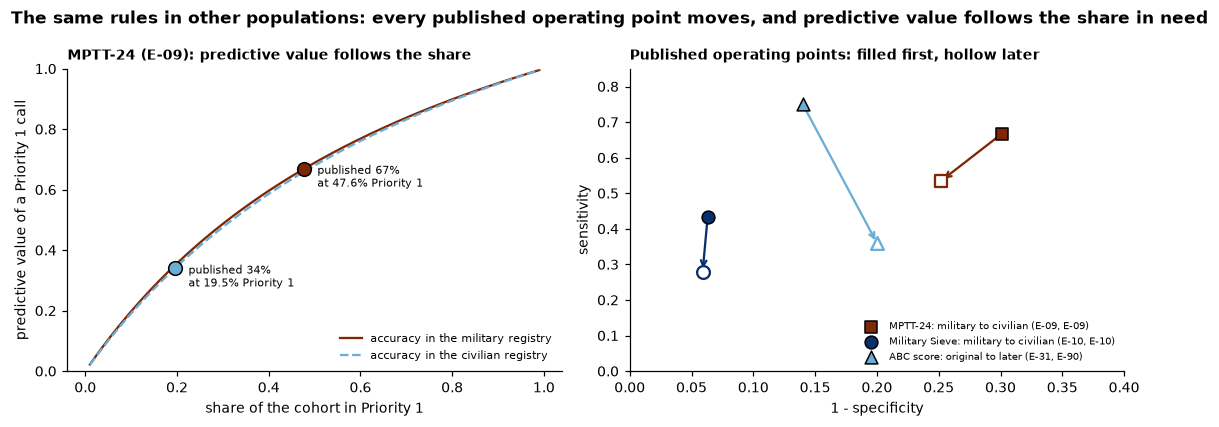

In [22]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.9))
prevalence = np.linspace(0.01, 0.99, 200)
for key, colour, style in (("MPTT-24, military", DARK, "-"), ("MPTT-24, civilian", PALE, "--")):
    p = rules.PUBLISHED[key]
    ax.plot(prevalence, rules.ppv(p.sensitivity, p.specificity, prevalence), style, color=colour, linewidth=1.5,
            label=f"accuracy in the {key.split(', ')[1]} registry")
    ax.scatter(p.prevalence, p.ppv, s=80, color=colour, edgecolor="black", zorder=3)
    ax.text(p.prevalence + 0.03, p.ppv - 0.06, f"published {p.ppv:.0%}\nat {p.prevalence:.1%} Priority 1", fontsize=7)
ax.set_xlabel("share of the cohort in Priority 1")
ax.set_ylabel("predictive value of a Priority 1 call")
ax.set_ylim(0, 1)
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("MPTT-24 (E-09): predictive value follows the share", loc="left", fontsize=9)

pairs = (("MPTT-24, military", "MPTT-24, civilian", DARK, "s"),
         ("Military Sieve, military", "Military Sieve, civilian", MID, "o"),
         ("ABC score, original", "ABC score, later", PALE, "^"))
for first, second, colour, marker in pairs:
    a, b = rules.PUBLISHED[first], rules.PUBLISHED[second]
    bx.annotate("", xy=(1 - b.specificity, b.sensitivity), xytext=(1 - a.specificity, a.sensitivity),
                arrowprops={"arrowstyle": "->", "color": colour, "linewidth": 1.5})
    bx.scatter(1 - a.specificity, a.sensitivity, s=70, color=colour, marker=marker, edgecolor="black", zorder=3,
               label=f"{a.rule}: {first.split(', ')[1]} to {second.split(', ')[1]} ({a.source}, {b.source})")
    bx.scatter(1 - b.specificity, b.sensitivity, s=70, facecolor="white", marker=marker, edgecolor=colour,
               linewidth=1.5, zorder=3)
bx.set_xlim(0, 0.4)
bx.set_ylim(0, 0.85)
bx.set_xlabel("1 - specificity")
bx.set_ylabel("sensitivity")
bx.legend(fontsize=6.5, frameon=False, loc="lower right")
bx.set_title("Published operating points: filled first, hollow later", loc="left", fontsize=9)
fig.suptitle("The same rules in other populations: every published operating point moves, and predictive value "
             "follows the share in need", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label: synthetic data can only confirm the model that made them. Axes 3, 4 and 5 are stated. Axis 7, the value of the decision, waits for the decision theory lens.

The diagnosis column scores the MPTT-24, under its default reading, against need for a life-saving intervention on all 100,000 synthetic casualties, every stream included. The generator's physiology is fitted to E-09, which was measured on hospital observations (E-11), so none of it is performance at the point of injury. The treatment column scores the ABC score against significant bleeding on the battle casualties, under the assumptions stated in the treatment case. Fit is native for both: deciding who is urgent and who is transfused is what these rules are for.

In [23]:
rules.seven_axes()

,diagnosis: MPTT-24,treatment: ABC score
axis,,
1 Discrimination (mechanism),"sensitivity 61.1%, specificity 72.8%: Priority 1 against need for a life-saving intervention, all 100,000 synthetic casualties","sensitivity 23.3%, specificity 93.2%: score 2 or more against significant bleeding, battle casualties, scan before hospital"
2 Calibration (mechanism),"Brier 0.292; it flags 16.2 points more of the casualties than are in need (share flagged minus share in need +0.162). A rule gives no probability, so the Br...",Brier 0.321; it flags 23.4 points fewer of the casualties than are in need (share flagged minus share in need -0.234)
3 Uncertainty expressed,"None: a priority, not a probability or an interval",None: activate or not
4 What it needed,"Rules only at the point of use. Its thresholds descend from the MPTT, derived by logistic regression on 3,654 registry patients with complete data (E-01, E-02)",Rules only at the point of use. Its published figures come from 596 patients (E-31)
5 Readability,"A medic can follow it at the point of care: six yes-or-no steps, one observation each","A medic can follow it: four yes-or-no items, counted"
"6 Robustness, setting changed (mechanism)","With the scan in hospital: sensitivity 61.1%, specificity 72.8%; Brier 0.292; it flags 16.2 points more of the casualties than are in need (share flagged mi...","With the scan in hospital: sensitivity 31.1%, specificity 94.1%; Brier 0.287; it flags 21.2 points fewer of the casualties than are in need (share flagged m..."
7 Decision value,Pending until lens 10,Pending until lens 10


These are the rows the comparison across lenses is built from. The baseline is the MPTT-24, the rule a medic would use (D-9). For the diagnosis case the rule is its own baseline, so the two columns agree. For the treatment case the baseline column scores the MPTT-24's Priority 1 against the same target, significant bleeding, on the same casualties.

In [24]:
card = pd.DataFrame([vars(row) for row in rules.LENS.scorecard()])
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan before hospital",0.611,0.611,mechanism,native,generator
1,diagnosis,"specificity, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan before hospital",0.728,0.728,mechanism,native,generator
2,diagnosis,"Brier score, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan before hospital",0.292,0.292,mechanism,native,generator
3,diagnosis,"share flagged minus share in need, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan before...",0.162,0.162,mechanism,native,generator
4,diagnosis,"sensitivity, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan in hospital",0.611,0.611,mechanism,native,generator
5,diagnosis,"specificity, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan in hospital",0.728,0.728,mechanism,native,generator
6,diagnosis,"Brier score, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan in hospital",0.292,0.292,mechanism,native,generator
7,diagnosis,"share flagged minus share in need, Priority 1 against need for a life-saving intervention, generator physiology fitted to hospital observations, scan in hos...",0.162,0.162,mechanism,native,generator
8,treatment,"sensitivity, ABC score 2 or more against significant bleeding, battle casualties, scan before hospital",0.233,0.620,mechanism,native,generator
9,treatment,"specificity, ABC score 2 or more against significant bleeding, battle casualties, scan before hospital",0.932,0.659,mechanism,native,generator


Two rows carry the lesson. The MPTT-24's figures on the generator do not change with the setting, because the generator's physiology does not; that axis says plainly what it cannot show. The ABC score's figures do change, because one of its four items is a scan. The ABC score's calibration rows are negative, which means it activates transfusion for fewer casualties than are bleeding significantly: on these synthetic casualties it under-calls.

**Teach back.** In one sentence, why is a rule's published accuracy a statement about a population, not about the rule?

## The brain analogy, and where it breaks

**What it resembles.** Deliberate, explicit reasoning. In the dual process model of diagnosis, repeated analytical working of the same presentation turns into recognition, and either mode can override the other (E-54). A rule is deliberation done once, written down and stored so that it can be run fast. The fast mode is not the faulty one: one review finds intuitive reasoning no more prone to error than deliberate reasoning (E-53).

**Where it breaks.** People do not apply rules without context. In ten Dutch hospitals, 4,950 patients, the field triage protocol applied on its own would have given an under-triage of 63.8% and an over-triage of 7.4%; in practice, with the protocol followed 73% of the time, they were 21.6% and 30.6%, as that study defines them (E-88). Practice departed from the rule, and found more of the severely injured at the cost of more patients sent on who were not. In the dual process model a departure of that kind is part of reasoning, not a breach of it. The rule in this notebook has no such override: it is exactly as blind as it was written.